# Pork Rasher Packaging Defect Detection with YOLOv8

This notebook downloads the labelled Roboflow dataset, checks its configuration,
trains a YOLOv8n baseline, reviews predictions, evaluates the model, inspects class
imbalance, and runs a second experiment with explicitly configured augmentation.

## Workflow

1. Set up the Python environment and verify GPU availability.
2. Download the dataset and validate its YAML configuration and folder structure.
3. Train the baseline model and review its learning curves.
4. Evaluate the baseline on validation data and inspect test predictions.
5. Review class distribution and training configuration.
6. Train and validate the corrected-augmentation experiment.

**Reproducibility:** This notebook uses Google Colab-style paths under `/content`.
If you run it elsewhere, update the dataset and output paths. Keep API keys private
and do not commit them to a public repository.


## 1. Environment setup

Ultralytics provides the YOLO API used to load pretrained weights and train an object detector using the dataset YAML configuration.

### Install and verify the YOLO training libraries

Install Ultralytics and the Roboflow SDK, then print the installed Ultralytics version. Run this setup cell before downloading data or training a model.

In [1]:
!pip install -q ultralytics roboflow

import ultralytics

print("Ultralytics version:", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 6.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.183


## 2. Compute environment

Check whether the runtime provides CUDA support before GPU-configured training.

### Check the available compute device

Inspect the installed PyTorch version and whether CUDA is available. The training cells specify `device=0`, which requires a compatible GPU runtime.

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. Dataset download

The dataset export includes images, YOLO-format labels and a YAML file defining split paths and class names.

### Download the Roboflow dataset

Authenticate with Roboflow, select the pork rasher packaging-defect project and download Version 1 in YOLO format. Keep API credentials private.

In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="siB1OGhXN0kGj0mPwzwM")
project = rf.workspace("ece4078h3").project("pork-rasher-error-packaging-rj5da")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pork-Rasher-Error(Packaging)-1 in yolov8:: 100%|██████████| 3915/3915 [00:00<00:00, 6634.11it/s]


## 4. Find the dataset configuration

### Locate and set the dataset YAML path

Search the Colab filesystem for `data.yaml` and assign the dataset configuration path. Confirm that the path exists and belongs to the intended dataset.

In [4]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file == "data.yaml":
            print(os.path.join(root, file))

DATA_YAML = "/content/Pork-Rasher-Error(Packaging)-1/data.yaml"

print(DATA_YAML)

/content/Pork-Rasher-Error(Packaging)-1/data.yaml
/content/Pork-Rasher-Error(Packaging)-1/data.yaml


## 5. Inspect the dataset YAML

### Inspect the dataset configuration

Print `data.yaml` to check training, validation and test paths, class count and class names before training.

In [5]:
with open(DATA_YAML, "r") as f:
    print(f.read())

names:
- loose-meat
- packaging-error
- twisted-meat
- unsealed
- wrinkle
nc: 5
roboflow:
  license: CC BY 4.0
  project: pork-rasher-error-packaging-rj5da
  url: https://universe.roboflow.com/ece4078h3/pork-rasher-error-packaging-rj5da/dataset/1
  version: 1
  workspace: ece4078h3
test: ../test/images
train: ../train/images
val: ../valid/images



## 6. Verify dataset structure

### Verify the dataset folders and image counts

List the dataset directory and count supported images in each available split. This helps identify incorrect paths or missing images.

In [6]:
import os
from pathlib import Path

data_root = Path(DATA_YAML).parent

print("Dataset directory:")
print(data_root)

for path in data_root.iterdir():
    print(path)


from pathlib import Path

image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG"]

for split in ["train", "valid", "val", "test"]:
    split_path = data_root / split

    if split_path.exists():
        count = sum(
            len(list((split_path / "images").glob(ext)))
            for ext in image_extensions
            if (split_path / "images").exists()
        )
        print(f"{split}: {count} images")

Dataset directory:
/content/Pork-Rasher-Error(Packaging)-1
/content/Pork-Rasher-Error(Packaging)-1/test
/content/Pork-Rasher-Error(Packaging)-1/train
/content/Pork-Rasher-Error(Packaging)-1/README.dataset.txt
/content/Pork-Rasher-Error(Packaging)-1/valid
/content/Pork-Rasher-Error(Packaging)-1/data.yaml
/content/Pork-Rasher-Error(Packaging)-1/README.roboflow.txt
train: 1764 images
valid: 115 images
test: 76 images


## 7. Load pretrained YOLOv8n weights

The model starts from pretrained weights and is fine-tuned on the custom defect classes rather than trained from scratch.

### Load the pretrained YOLOv8n model

Initialise YOLOv8n using pretrained weights. Fine-tuning provides the baseline detector for the custom pork rasher classes.

In [7]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

## 8. Train the baseline model

This run establishes a baseline against which the augmentation experiment can be compared.

### Train the baseline YOLOv8n detector

Fine-tune the model using the dataset YAML. This run uses 50 epochs, 640-pixel images, batch size 16 and early stopping patience of 10. Results are saved under `/content/mma3001_results/yolov8n_baseline`.

In [8]:
results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/mma3001_results",
    name="yolov8n_baseline",
    patience=10,
    plots=True
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pork-Rasher-Error(Packaging)-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=64, nms=None, ops

## 9. Review training curves

### Review the baseline training curves

Display the training-results plot produced by Ultralytics. Use the loss and validation curves to look for convergence or overfitting.

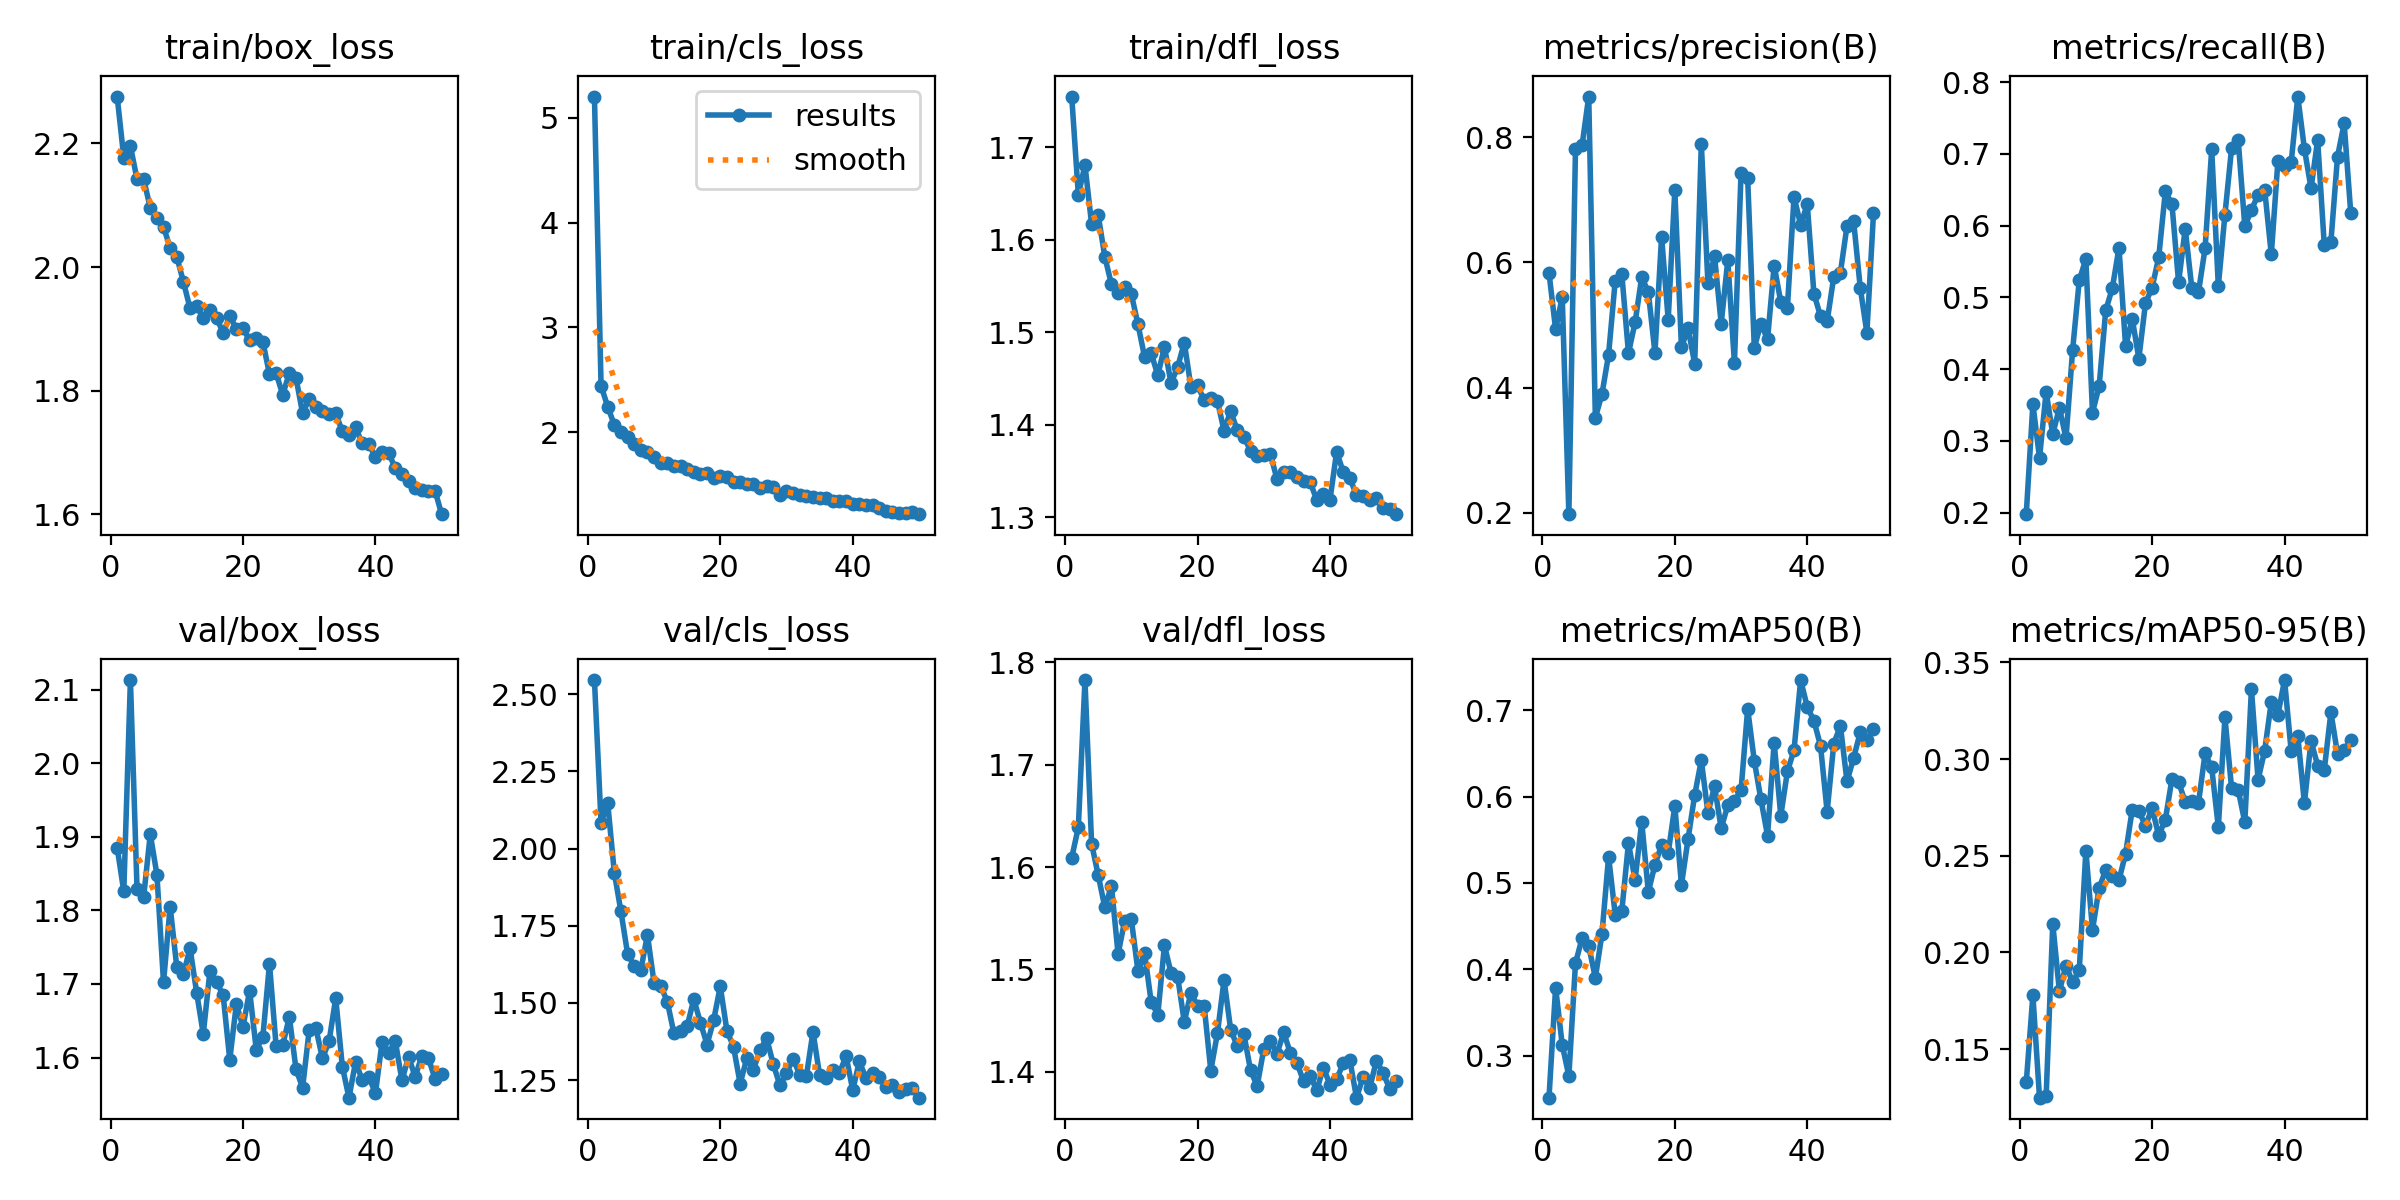

In [9]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/mma3001_results/yolov8n_baseline/results.png"
    )
)

## 10. Validate the baseline model

### Validate the baseline model

Load the best baseline checkpoint and evaluate it on the validation split. Print mAP@50 and mAP@50–95.

In [10]:
best_model = YOLO(
    "/content/mma3001_results/yolov8n_baseline/weights/best.pt"
)

metrics = best_model.val(
    data=DATA_YAML,
    split="val"
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1989.7±786.1 MB/s, size: 51.1 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-1/valid/labels.cache... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 34.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.5it/s 3.2s
                   all        115        143      0.694      0.685      0.704      0.341
            loose-meat          5          5      0.656      0.769      0.762      0.348
       packaging-error         30         45      0.614      0.142      0.305      0.106
          twisted-meat          4          5      0.733          1      0.862      0.368
              unsealed         85         88      0.772       0.83      0.888      0.541
Speed: 4.3ms preprocess, 6.

## 11. Predict on test images

### Run baseline inference on test images

Generate predictions for the test images using confidence threshold 0.25. Save annotated images and prediction labels for qualitative inspection. This cell does not itself calculate final test metrics.

In [11]:
test_results = best_model.predict(
    source=f"{data_root}/test/images",
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True
)


image 1/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_102_jpg.rf.8659eac39d6481b97dd7cd9cd5b53d10.jpg: 640x640 1 unsealed, 12.5ms
image 2/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_121_jpg.rf.b9703132d3c2ed0d47b4abbff0161da4.jpg: 640x640 1 twisted-meat, 12.7ms
image 3/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1271_jpg.rf.22e9aa3a2caa406e08bbe0e9cc1979a7.jpg: 640x640 1 unsealed, 12.5ms
image 4/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1298_jpg.rf.dd1b58a843b4aa0fa35a3deb2d94a00b.jpg: 640x640 2 packaging-errors, 13.2ms
image 5/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1405_jpg.rf.dffa5de43a67cd0101bc0d29a4761afe.jpg: 640x640 1 unsealed, 12.5ms
image 6/76 /content/Pork-Rasher-Error(Packaging)-1/test/images/frame_with_red_1427_jpg.rf.bbc3b5eb81e27d8beaad124f9cd2cbff.jpg: 640x640 1 unsealed, 13.0ms
image 7/76 /content/Pork-Rasher-Error(Packaging)-1/test/ima

### Inspect a sample baseline prediction

Count the saved prediction images and display the first available result. Check that boxes and labels align with the image.

Number of prediction images: 76


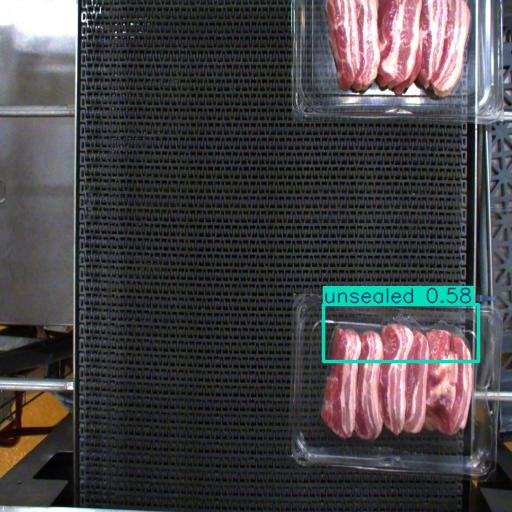

In [12]:
from pathlib import Path
from IPython.display import Image, display

prediction_dir = Path("/content/runs/detect/predict")

images = list(prediction_dir.glob("*.jpg")) + list(prediction_dir.glob("*.png"))

print("Number of prediction images:", len(images))

if images:
    display(Image(filename=str(images[0])))

## 12. Inspect class distribution

### Evaluate the baseline model on the held-out test split

Run Ultralytics validation against the test split and save plots and JSON output. Keep the test set separate from model tuning.

In [13]:
from ultralytics import YOLO

model = YOLO(
    "/content/mma3001_results/yolov8n_baseline/weights/best.pt"
)

model.val(
    data="/content/Pork-Rasher-Error(Packaging)-1/data.yaml",
    split="test",
    plots=True,
    save_json=True
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1583.1±665.9 MB/s, size: 50.2 KB)
val: Scanning /content/Pork-Rasher-Error(Packaging)-1/test/labels... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 1.7Kit/s 0.0s
val: New cache created: /content/Pork-Rasher-Error(Packaging)-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.8it/s 2.8s
                   all         76         91      0.696      0.509      0.662       0.27
            loose-meat          2          3      0.725      0.667      0.863      0.283
       packaging-error         22         29      0.513       0.11      0.429      0.123
          twisted-meat          7          7      0.689      0.571      0.569      0.258
              unsealed         51         52 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a9623f02200>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

### Audit dataset and baseline model configuration

Print dataset class names and training-instance counts, then inspect the trained model and saved training arguments for reproducibility.

In [14]:
from pathlib import Path
from collections import Counter
import yaml

dataset_path = Path(
    "/content/Pork-Rasher-Error(Packaging)-1"
)

# Load class names
with open(dataset_path / "data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("Classes:")
for i, name in enumerate(data["names"]):
    print(f"{i}: {name}")

# Count training instances
label_dir = dataset_path / "train" / "labels"

class_counts = Counter()

for label_file in label_dir.glob("*.txt"):
    with open(label_file, "r") as f:
        for line in f:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

print("\nTraining instances:")
for class_id, count in sorted(class_counts.items()):
    name = data["names"][class_id]
    print(f"{name}: {count}")

Classes:
0: loose-meat
1: packaging-error
2: twisted-meat
3: unsealed
4: wrinkle

Training instances:
loose-meat: 127
packaging-error: 1372
twisted-meat: 236
unsealed: 479
wrinkle: 18


### Train and validate the corrected-augmentation experiment

Train a fresh YOLOv8n model with explicitly configured augmentations, save the best checkpoint, then evaluate it on the validation split and print overall and per-class metrics. Use the test split for final reporting rather than repeated tuning.

In [15]:
from pathlib import Path
import yaml
from ultralytics import YOLO

dataset_path = Path(
    "/content/Pork-Rasher-Error(Packaging)-1"
)

model_path = (
    "/content/mma3001_results/"
    "yolov8n_baseline/weights/best.pt"
)

# 1. Inspect dataset configuration
with open(dataset_path / "data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("DATASET CONFIGURATION")
print("Names:", data.get("names"))
print("Number of classes:", data.get("nc"))
print("Train:", data.get("train"))
print("Validation:", data.get("val"))
print("Test:", data.get("test"))

# 2. Inspect trained model
model = YOLO(model_path)

print("\nTRAINED MODEL")
print("Model class names:", model.names)
print("Number of model classes:", len(model.names))

# 3. Inspect saved training arguments
args_path = (
    Path("/content/mma3001_results/")
    / "yolov8n_baseline" / "args.yaml"
)

if args_path.exists():
    with open(args_path, "r") as f:
        args = yaml.safe_load(f)

    print("\nTRAINING ARGUMENTS")
    for key in [
        "model", "data", "epochs", "imgsz",
        "batch", "patience", "augment",
        "close_mosaic", "fliplr", "flipud",
        "degrees", "scale", "mosaic"
    ]:
        print(f"{key}: {args.get(key)}")
else:
    print("\nargs.yaml not found; inspect the run folder.")

DATASET CONFIGURATION
Names: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']
Number of classes: 5
Train: ../train/images
Validation: ../valid/images
Test: ../test/images

TRAINED MODEL
Model class names: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed', 4: 'wrinkle'}
Number of model classes: 5

TRAINING ARGUMENTS
model: yolov8n.pt
data: /content/Pork-Rasher-Error(Packaging)-1/data.yaml
epochs: 50
imgsz: 640
batch: 16
patience: 10
augment: False
close_mosaic: 10
fliplr: 0.5
flipud: 0.0
degrees: 0.0
scale: 0.5
mosaic: 1.0


### Code cell

This cell performs the operation described by the surrounding section.

In [16]:

from ultralytics import YOLO
import os

# Dataset path
DATA_YAML = "/content/Pork-Rasher-Error(Packaging)-1/data.yaml"

# Output directory
PROJECT_DIR = "/content/mma3001_results"
RUN_NAME = "yolov8n_corrected_augmented"

# Check that the dataset configuration exists
if not os.path.exists(DATA_YAML):
    raise FileNotFoundError(
        f"Dataset configuration not found: {DATA_YAML}\n"
        "Update DATA_YAML to your actual dataset path."
    )

# Start from the same pretrained YOLOv8n model
model_aug = YOLO("yolov8n.pt")

# Experiment 2: explicit data augmentation
results_aug = model_aug.train(
    data=DATA_YAML,

    # Training settings
    epochs=60,
    imgsz=640,
    batch=16,
    device=0,
    patience=15,

    # Save results
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,

    # Explicit augmentation
    augment=True,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    degrees=5.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    mosaic=1.0,
    close_mosaic=10,

    # Reproducibility and plots
    plots=True,
    seed=42
)

# Best model checkpoint
BEST_MODEL = os.path.join(
    PROJECT_DIR, RUN_NAME, "weights", "best.pt"
)

if os.path.exists(BEST_MODEL):
    print("\nTraining completed successfully.")
    print(f"Best model saved at: {BEST_MODEL}")
else:
    raise FileNotFoundError(
        f"Best model checkpoint not found: {BEST_MODEL}"
    )




from ultralytics import YOLO
import os

# Use the same dataset configuration as training
DATA_YAML = "/content/Pork-Rasher-Error(Packaging)-1/data.yaml"

BEST_MODEL = (
    "/content/mma3001_results/"
    "yolov8n_corrected_augmented/weights/best.pt"
)

# Check files exist
if not os.path.exists(DATA_YAML):
    raise FileNotFoundError(f"Dataset not found: {DATA_YAML}")

if not os.path.exists(BEST_MODEL):
    raise FileNotFoundError(f"Model not found: {BEST_MODEL}")

# Load the best checkpoint
aug_model = YOLO(BEST_MODEL)

# Validate using consistent evaluation settings
metrics_aug = aug_model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    conf=0.001,
    iou=0.7,
    plots=True,
    project="/content/mma3001_results",
    name="yolov8n_corrected_augmented_val"
)

# Print overall metrics
print("\n" + "=" * 45)
print("CORRECTED AUGMENTED MODEL — VALIDATION RESULTS")
print("=" * 45)

print(f"Precision:  {metrics_aug.box.mp:.4f}")
print(f"Recall:     {metrics_aug.box.mr:.4f}")
print(f"mAP@50:     {metrics_aug.box.map50:.4f}")
print(f"mAP@50-95:  {metrics_aug.box.map:.4f}")

print("\nPer-class mAP@50:")
for class_id, class_name in aug_model.names.items():
    if class_id < len(metrics_aug.box.maps):
        print(
            f"{class_name}: "
            f"{metrics_aug.box.maps[class_id]:.4f}"
        )

print("\nValidation results and plots saved.")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pork-Rasher-Error(Packaging)-1/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_corrected_augmented, nbs=64, nms=